<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo II: Sesgos, justicia, y discriminación <h2></center>

# `Instrucciones Generales`


## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondas con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

---

## `Contexto`

Los modelos de apoyo diagnóstico en salud tienen el potencial de mejorar distintos ámbitos asociados a la eficacia médica: pueden ayudar a priorizar la atención y mejorar la detección temprana de casos, pero también tienen el potencial de fallar de forma desigual entre grupos de pacientes. Un caso de esto es el algoritmo analizado por Obermeyer et al. (2019), usado en hospitales de EE.UU. para decidir qué pacientes necesitan programas de manejo de enfermedades crónicas: al usar el gasto histórico en salud como proxy de necesidad médica, el modelo subestima la gravedad de los pacientes afroamericanos, quienes históricamente reciben menos atención médica por menor acceso al sistema, no por estar más sanos.

El dataset sintético *Breast Cancer Prediction* contiene distintas variables que pueden ayudar a la detección de cáncer de mama, siendo **Cancer** la variable objetivo con la que entrenarán su modelo. La preocupación aquí es análoga: un modelo que clasifique mal, o que rinda de forma distinta entre subgrupos de pacientes, puede traducirse directamente en diagnósticos tardíos o en una falsa sensación de seguridad para algún grupo en desventaja.

`links`

- [Fuente de los datos](https://www.kaggle.com/datasets/mobeenfatimah/breast-cancer-prediction-dataset-10000-patient)
- [Link a los datos](https://drive.google.com/file/d/12E5CepN-3pv4ULE9dtd2Ty6WllUtW8pi/view?usp=drive_link)
- [Link al diccionario de datos](https://drive.google.com/file/d/1eOnjN59tlAEeeGagbSUPX-5xJnx47iUY/view?usp=sharing)
---

## Parte 1
Antes de iniciar el trabajo deben comprender los datos: de dónde provienen, qué limitaciones podrían tener, qué variables incluyen, si siguen algún estándar de calidad y cuánto hay que limpiarlos. Antes de escribir cualquier línea de código, lean y discutan esta información.

### **RESPONDER**

1. Discutan los objetivos de este dataset, los motivos detrás de su creación y las limitaciones que implica el hecho de ser sintético. Utilicen referencias para justificar su punto y expliquen para qué serviría entrenar un clasificador automático de este tipo.

El dataset se encuentra almacenado en la plataforma *Kaggle*. El objetivo de estos datasets proporcionados por empresas, estudiantes y ex-estudiantes es permitir resolver problemas o utilizarlos como simulaciones de practica. Ser de utilidad para los estudiantes que se inician en el *machine learning* aprenden un nuevo lenguaje de programación o trabajan con una nueva herramienta. [1]


Los datos sinteticos son datos artificiales diseñados para imitar datos de la vida real. Se generan a través de métodos estadísticos o mediante el uso de técnicas de inteligencia artificial. [2]

Sus desventaja mas grande es la falta de realismo y precisión, si bien replican patrones y capturan correlaciones, generar datos sintéticos realistas que capturen los matices de los datos del mundo real es una tarea compleja. Esto deriva a que no tengamos certeza si estos reflejan fielmente las tendencias de los datos reales, lo que no nos garantiza de que un modelo entrenado con datos sintéticos sea preciso al aplicarse al mundo real.

Los modelos generativos de datos sintéticos buscan tendencias y patrones comunes en los datos reales, pero pueden pasar por alto matices sutiles o posibles anomalías presentes en estos. La generación de datos sintéticos depende en gran medida de los datos reales subyacentes. Si los datos reales son incompletos o inexactos, los datos generados a partir de ellos tampoco serán perfectos. Además, si los datos reales cambian con el tiempo, los datos sintéticos generados a partir de ellos deben revisarse y actualizarse periódicamente para garantizar su precisión y fiabilidad. [3]

Referencia:
1. https://careerkarma.com/wiki/kaggle-datasets/
2. https://www.ibm.com/mx-es/think/topics/synthetic-data
3. https://syntheticus.ai/blog/the-benefits-and-limitations-of-generating-synthetic-data


## Librerias y configuraciones

In [53]:
# imports iniciales
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# sklearn - importa aquí las librerías necesarias
import sklearn
from sklearn import metrics
from sklearn.tree import plot_tree
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, confusion_matrix


# aequitas
from aequitas.group import Group
from aequitas.bias import Bias

# aif360
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.postprocessing.eq_odds_postprocessing import EqOddsPostprocessing
from aif360.algorithms.preprocessing import Reweighing
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.datasets import BinaryLabelDataset


import warnings
warnings.filterwarnings("ignore")

## Parte 2: Realicen el preprocesamiento de los datos y entrenen un árbol de decisión para predecir cáncer de mama a partir de la variable objetivo **Cancer**. Reporten el *accuracy* y la matriz de confusión sobre los datos de testeo.

*Puede reutilizar el jupyter o trabajar con el mismo jupyter de la entrega anterior, puede entregar una carpeta con ambos jupyter y funcioness*


### Indicaciones

- El preprocesamiento debe incluir al menos: manejo de valores faltantes, codificación de variables categóricas, normalización de variables numéricas y tratamiento de valores extremos.

- Utilicen `random_state` o semillas donde corresponda para garantizar la reproducibilidad de los resultados.

- La variable **Cancer** está desbalanceada. Investiguen el argumento `class_weight='balanced'` de sklearn para manejar este problema y aplíquenlo si lo consideran pertinente.

### **RESPONDER**

2.1 Expliquen y justifiquen los pasos del preprocesamiento.

2.2 Observando solo la matriz de confusión, ¿podemos concluir que el modelo tiene el mismo rendimiento para todos los grupos demográficos? Desarrollen y argumenten su respuesta.


In [2]:
# Reutilizamos la carga de datos del jupyter anterior

# Cargamos la ruta
path = "breast_cancer_prediction.csv"

# Leemos el archivo csv y lo guardamos en un dataframe
df = pd.read_csv(path)

# Mostramos las 5 primeras filas
df.head()

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919


In [3]:
# df.columns

In [4]:
#df.info()

**1. Clasificación de variables.**

Variables númericas (cuantitativas):

- ID del paciente (Número entero) (Funciona como un identificador, no un número que podamos promediar).
- Edad (Número entero).
- BMI (Índice de Masa Corporal) (Número decimal).
- Tamaño del tumor en cm (Número decimal).
- Cancer (Número entero).
- Presión arterial (Número entero).
- Colesterol (Número entero).
- Número de dias de ejercicio a la semana (Número entero).
- Ingresos anuales en dólares estadounidenses (Número entero).

Variables categóricas(cualitativas):
- Género.
- Historial médico familiar.
- Fumar.
- Consumo de alcohol.
- Actividad física.
- Terapia hormonal.
- Estado menopáusico.
- Mutación genética.
- Afección de los ganglios linfáticos.
- Resultados de mamografía.
- Resultados de biopsia.
- Etapa del cancer.
- Diabetes.
- Historial de lactancia materna.

**2. Atributos demográficos y sensibles.**

En el contexto médico, los atributos demográficos se refieren a la información personal y de identificación que se compilan durante su registro al sistema médico.

- Edad.
- Género.
- Ingresos anuales en dálares estadounidenses (contextualiza la posición econámica del paciente).

Mientras que los atributos sensibles, se refieren a aquellos que su divulgación puede causar daño, discriminación o violación a la privacidad del paciente.

- Cancer.
- Fumar.
- Consumo de alcohol.
- Terapia hormonal.
- Estado menopáusico.
- Mutación genética.
- Resultados de mamografía.
- Resultados de biopsia.
- Etapa del cancer.
- Diabetes.

**3. Datos en formato incorrecto.**

- ID del paciente. Esta variable se encuentra en formato de número entero, esto significa que es posible aplicarle estadisticas como mediana, moda o promedio. Sin embargo, esta variable tiene como finalidad representar e identificar al paciente, por lo que, un string es la mejor opción para evitar operaciones estadisticas innecesarias sobre la columna.

- Cáncer. Esta variable se encuentra representada por un número entero, sin embargo, creemos que un tipo de dato categórico sería lo mejor para representar a las dos opciones: "Tiene cancer" o "No tiene cancer", además no corremos el riesgo (como en la variable anterior) de que se intente realizar operaciones estadísticas inservibles sobre esta.

In [5]:
# 1. Cambiar "Cancer" a tipo categórico
df["Cancer"] = df["Cancer"].astype(str)

# 2. Cambiar "Patient_ID" a string
df["Patient_ID"] = df["Patient_ID"].astype(str)

### Manejo de valores faltantes

In [6]:
# Valores  nulos

df.isnull().sum()

Patient_ID                  0
Age                         0
Gender                      0
BMI                       300
Family_History              0
Smoking                     0
Alcohol_Consumption       300
Physical_Activity         300
Hormone_Therapy           300
Menopause_Status            0
Genetic_Mutation            0
Tumor_Size_cm             300
Lymph_Node_Involvement      0
Mammogram_Result            0
Biopsy_Result               0
Cancer_Stage                0
Cancer                      0
Blood_Pressure              0
Cholesterol                 0
Diabetes                    0
Exercise_Days_Per_Week      0
Breastfeeding_History       0
Annual_Income_USD           0
dtype: int64

Las variables BMI (Índice de Masa Corporal), Alcohol_Consumption (Consumo de alcohol), Physical_Activity (Actividad física), Hormone_Therapy (Terapia de hormonas), Tumor_Size_cm (Tamaño del tumor en cm), son las columnas que poseen 300 filas de datos nulos.

Aquí reflexionamos bastante en sobre que hacer con los nulos ¿Insertamos el promedio?¿El valor que más se repite?¿Insertamos un 0?
Nuestra conclusion fue tomar todos esos valoes nulos y llevarlos a 0. Ahora, podríamos pensar que esto se puede traducir en falta de información para un modelo o análisis, sin embargo, en todas las opciones posibles perderíamos algo pero se adapta también a lo que ya nos entrega el dataset.

Por otro lado si insertamos el promedio obtenemos informacion que no refleja la realidad y estariamos asignando datos falsos a personas reales. O recordando el algoritmo de SISFOH visto en clases, en relación a la asignación de pensiones. Si una persona dejaba "espacios en blanco", en vez de colocar 0, lo podrian rellenar con la moda y eso perjudica que le den la pensión, es decir, si la moda era "tener casa propia", y una persona dejo ese espacio sin algún dato, luego se coloca la moda que es tener una casa, perjudica que le puedan asignar una pensión. 

In [7]:
# cols_null = ['BMI', 'Alcohol_Consumption', 'Physical_Activity', 'Hormone_Therapy', 'Tumor_Size_cm']

# for c in cols_null:
#     df[c] = df[c].fillna(0)

Verificamos no tener valores nulos en las columnas

In [8]:
# df.isnull().sum()

Patient_ID                0
Age                       0
Gender                    0
BMI                       0
Family_History            0
Smoking                   0
Alcohol_Consumption       0
Physical_Activity         0
Hormone_Therapy           0
Menopause_Status          0
Genetic_Mutation          0
Tumor_Size_cm             0
Lymph_Node_Involvement    0
Mammogram_Result          0
Biopsy_Result             0
Cancer_Stage              0
Cancer                    0
Blood_Pressure            0
Cholesterol               0
Diabetes                  0
Exercise_Days_Per_Week    0
Breastfeeding_History     0
Annual_Income_USD         0
dtype: int64

### Codificación de variables categóricas

La columna Patient_ID es funciona como identificador de cada paciente, este se vuelve útil dependiendo del contexto. Si quisieramos saber la edad, género, su hostira familiar, etc. Serviría para otros casos pero no en un árbol de desición no, por eso eliminamos esta columa.

Anteriormente se reviso los tipos de datos de cada columna. Pudimos notar que algunas eran columnas numéricas pero la mayoría eran datos categóricos o de tipo objetc (str). Como un árbol de desición no entiende estos valores, decidimos ayudarnos de la función map para mapear cada datos de manera binaria o ascendente. 

Decidimos hacerlo de manera biniria por que en algunas columnas salía explicitamente 'Yes' o 'No' meientras que en otras salían solo dos categorias como Female/Male o Positive/Negative. Además habían columnas que tenían mas de dos categorias y las fuimos asignando de forma asendente partiendo siempre desde el 0. 

Por último, usamos get_dummies que lleva los datos categoricos a binarios. 

In [44]:
###ARREGLAR ESTOOOOOOOOOOOOO
# 1. Eliminar identificador y variables con fuga de información
df = df.drop(columns=['Patient_ID', 'Biopsy_Result', 'Cancer_Stage'], errors='ignore')

# 2. Reemplazar texto por números sin perder datos
diccionario_reemplazo = {
    'Yes': 1, 'No': 0,
    'Female': 1, 'Male': 0,
    'Pre': 1, 'Post': 0,
    'Positive': 1, 'Negative': 0,
    'Low': 0, 'Moderate': 1, 'High': 2,
    'Normal': 0, 'Suspicious': 1, 'Abnormal': 2
}
df = df.replace(diccionario_reemplazo)

# 3. Convertir variables categóricas restantes
df = pd.get_dummies(df, drop_first=True, dtype=int)

# 4. Rellenar nulos al final
df = df.fillna(0)

In [45]:

df_raw = df.copy()

In [46]:
df.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Mammogram_Result,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
0,0.796875,1,0.616780,1,1,1.0,2.0,0.0,0,1,...,1,1,0.566667,0.217647,0,1.000000,0.639391,1,0,0
1,0.218750,0,0.589569,0,0,0.0,2.0,0.0,0,0,...,0,0,0.155556,0.582353,1,1.000000,0.323129,0,0,1
2,0.937500,1,0.469388,0,0,0.0,2.0,0.0,1,0,...,1,0,0.788889,0.852941,0,0.142857,0.323129,0,0,1
3,0.312500,1,0.607710,1,1,0.0,1.0,0.0,0,0,...,0,0,0.666667,0.294118,0,1.000000,0.392780,0,0,1
4,0.359375,1,0.648526,1,1,0.0,1.0,0.0,0,0,...,0,0,0.222222,0.800000,0,0.000000,0.562373,0,0,1


In [47]:
# Notar que ahora todas nuestras columnas son numéricas
df.dtypes

Age                                     float64
Gender                                    int64
BMI                                     float64
Family_History                            int64
Smoking                                   int64
Alcohol_Consumption                     float64
Physical_Activity                       float64
Hormone_Therapy                         float64
Menopause_Status                          int64
Genetic_Mutation                          int64
Tumor_Size_cm                           float64
Lymph_Node_Involvement                    int64
Mammogram_Result                          int64
Cancer                                    int64
Blood_Pressure                          float64
Cholesterol                             float64
Diabetes                                  int64
Exercise_Days_Per_Week                  float64
Annual_Income_USD                       float64
Breastfeeding_History_No                  int64
Breastfeeding_History_Not Applicable    

### Normalización de variables numéricas

In [49]:
# 1. Separar X e y
X = df.drop(columns=['Cancer'])
y = df['Cancer']

# 2. Dividir PRIMERO en Train y Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Escalar DESPUÉS (solo usando datos de entrenamiento)
columnas_norm = ['Age', 'BMI', 'Tumor_Size_cm', 'Blood_Pressure', 'Cholesterol', 
                 'Exercise_Days_Per_Week', 'Annual_Income_USD']

scaler = MinMaxScaler()
X_train[columnas_norm] = scaler.fit_transform(X_train[columnas_norm])
X_test[columnas_norm] = scaler.transform(X_test[columnas_norm])

In [50]:
df.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Mammogram_Result,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
0,0.796875,1,0.616780,1,1,1.0,2.0,0.0,0,1,...,1,1,0.566667,0.217647,0,1.000000,0.639391,1,0,0
1,0.218750,0,0.589569,0,0,0.0,2.0,0.0,0,0,...,0,0,0.155556,0.582353,1,1.000000,0.323129,0,0,1
2,0.937500,1,0.469388,0,0,0.0,2.0,0.0,1,0,...,1,0,0.788889,0.852941,0,0.142857,0.323129,0,0,1
3,0.312500,1,0.607710,1,1,0.0,1.0,0.0,0,0,...,0,0,0.666667,0.294118,0,1.000000,0.392780,0,0,1
4,0.359375,1,0.648526,1,1,0.0,1.0,0.0,0,0,...,0,0,0.222222,0.800000,0,0.000000,0.562373,0,0,1


### Tratamiento de valores extremos.

In [54]:
# Entrenar modelo
modelo = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo.fit(X_train, y_train)

# Predicción
y_pred = modelo.predict(X_test)

# Mostrar resultados
print("=== RESULTADOS PARTE 2 ===")
print("Accuracy Global:", round(accuracy_score(y_test, y_pred), 4))
print("\nMatriz de Confusión Global:")
print(confusion_matrix(y_test, y_pred))

=== RESULTADOS PARTE 2 ===
Accuracy Global: 0.8585

Matriz de Confusión Global:
[[1508  105]
 [ 178  209]]


Notar que solo dos columnas tienen outliers y son BMI y Tumor_Size_cm

In [55]:
cols_outliers = ['BMI', 'Tumor_Size_cm']

# Obtenemos el IQR que es la diferencia entre el tercer y primer cuartil, así vermos que tan dispersos estan los datos
for c in cols_outliers:
    Q1 = df[c].quantile(0.25)
    Q3 = df[c].quantile(0.75)
    IQR = Q3 - Q1

    # Luego se consideran outliers los valores abajo del limite inferior (LI) y arriba del limite superior
    lim_inferior = Q1 - 1.5 * IQR
    lim_superior = Q3 + 1.5 * IQR
    
    # Revisamos cada fila de las columnas, si el valor es mayor a limite superior se reemplaza por el limite superior
    # es análogo con el límite inferior
    df.loc[df[col] > lim_superior, col] = lim_superior
    df.loc[df[col] < lim_inferior, col] = lim_inferior

# Árbol de desición

In [57]:
# Seleccionamos las variables predictoras y la variable dependiente
X = df.drop(columns=['Cancer', 'Biopsy_Result', 'Cancer_Stage'], errors='ignore')
y = df['Cancer'] 

# Separamos en datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=42)

https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html#sklearn.utils.class_weight.compute_class_weight

In [58]:
# Definimos el modelo y especificamos sus hiperparámetros
classifier = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)

# Ajustamos a los datos de entrenamiento
classifier.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


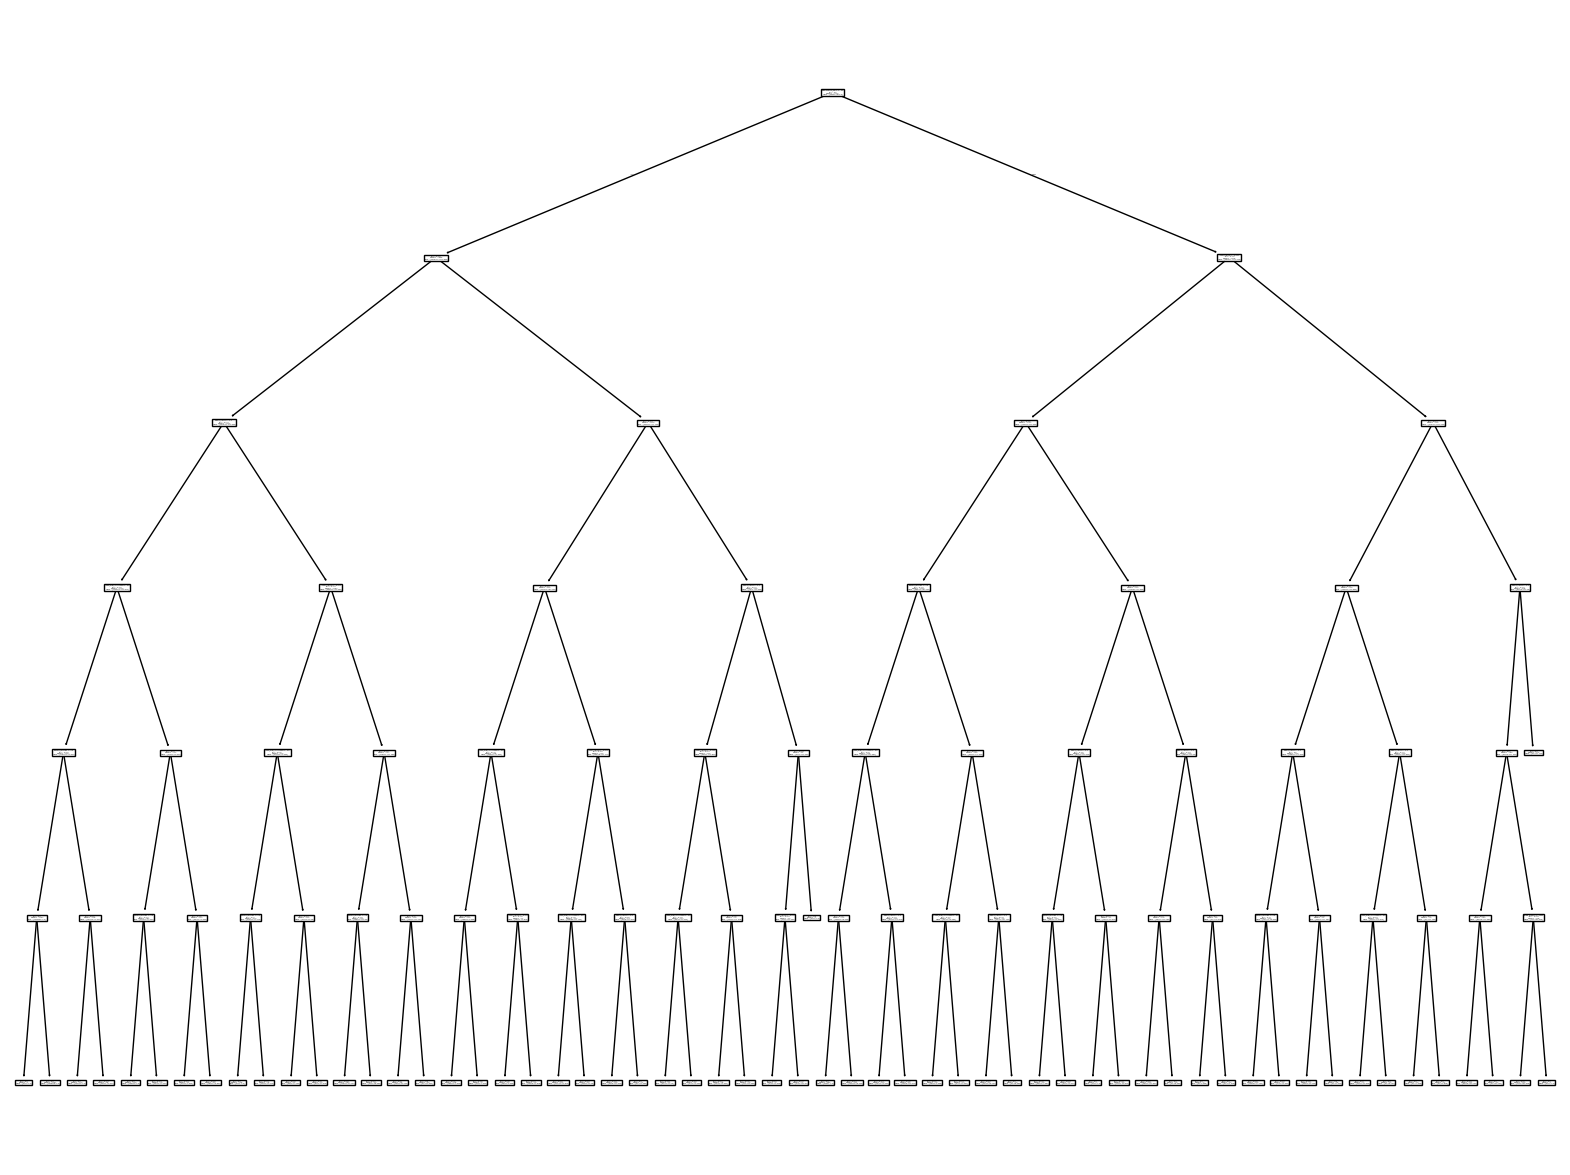

In [59]:
fig = plt.figure(figsize=(20,15))
ax = fig.add_subplot(111)
plot_tree(classifier, ax=ax, feature_names=X_train.columns)
plt.show()

In [60]:
# Predecimos las categorías para el dataset de prueba
y_pred_test = classifier.predict(X_test)

In [61]:
X_train.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Lymph_Node_Involvement,Mammogram_Result,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
9069,0.875000,1,0.580499,0,0,1.0,0.0,1.0,0,0,...,0,2,0.944444,0.694118,0,0.142857,0.600864,0,0,1
2603,0.093750,1,0.360544,0,0,1.0,0.0,0.0,0,0,...,0,1,0.800000,0.582353,0,0.571429,0.323129,1,0,0
7738,0.140625,1,0.555556,0,0,0.0,1.0,0.0,1,0,...,0,2,0.766667,0.517647,0,0.428571,0.730899,1,0,0
1579,0.406250,1,0.639456,0,0,0.0,0.0,0.0,0,0,...,0,0,0.655556,0.323529,0,1.000000,0.409203,0,0,1
5058,0.437500,1,0.566893,0,0,1.0,0.0,0.0,1,0,...,0,0,0.088889,0.370588,0,0.714286,0.739879,0,0,1


Ahora graficamos y analizamos la matriz de confusión

Matriz de confusion:
[[2142  309]
 [  93  456]]


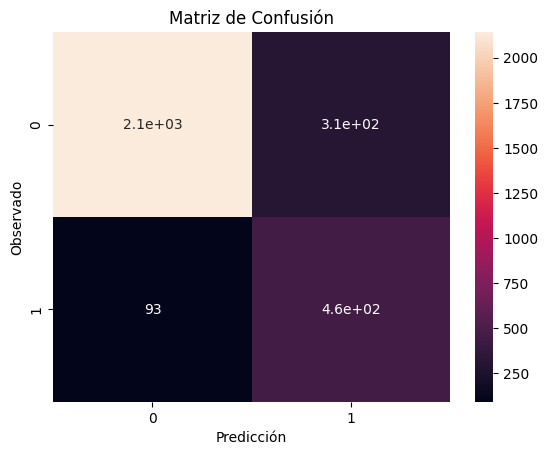

Accuracy: 0.87
Recall: 0.83
Precision: 0.596
F score: 0.69
              precision    recall  f1-score   support

           0       0.96      0.87      0.91      2451
           1       0.60      0.83      0.69       549

    accuracy                           0.87      3000
   macro avg       0.78      0.85      0.80      3000
weighted avg       0.89      0.87      0.87      3000



In [62]:
cm = metrics.confusion_matrix(y_test, y_pred_test)
print('Matriz de confusion:')
print(cm)

# Graficamos la matriz de confusión
sns.heatmap(cm, annot=True)
plt.ylabel('Observado')
plt.xlabel('Predicción')
plt.title('Matriz de Confusión')
plt.show()

accuracy=metrics.accuracy_score(y_test,y_pred_test)
print('Accuracy:', round(accuracy,2))

recall=metrics.recall_score(y_test,y_pred_test)
print('Recall:', round(recall,2))

precision=metrics.precision_score(y_test,y_pred_test)
print('Precision:', round(precision,3)) 

fscore=metrics.f1_score(y_test,y_pred_test)
print('F score:', round(fscore,2))

print(metrics.classification_report(y_test, y_pred_test))

Cuando se hizo por primera vez el modelo, solo se quitó del DataFrame la columna cancer. El arbol tenía 3 nodos y todas las medidas estaban dando 1.0. Esto pareció muy sospechoso entonces nos fijamos que el modelo le estaba dando importancia a las columnas Biopsy_Result y  Cancer_Stage, así que las eliminamos, luego seguimos con el modelo de manera normal y nos entregó los resultados anteriores.

Si nos fijamos en la diagonal de la matriz:
- Verdaderos positivos: 2142
- Verdaderos negativos: 456

Mientras que las otras diagonales corresponden a:
- Falsos positivos: 309
- Falsos negativos: 93

El acurracy es de un 87%, su nivel de acierto y la diagonal principal de la matriz también da valores altos 2142 y 456 en comparación a los otros valores de esta. Pero no solo basta con acertar, también juega la precisión del comedio que es de un 60% a la hora de estimar si una persona es diagnosticada con cancer de mama o no. La sensibilidad en un 83%, es decir, que tantos verdaderos positivos efectivamente acierta el modelo. Por otro lado tenemos f1-score de un 69% que es un porcentaje bueno al combinar la precisión y sensibilidad del modelo


## Parte 3: Evalúen las predicciones del modelo mediante las métricas de *fairness* de Aequitas.

### **Indicaciones**

Consideren como posibles atributos demográficos sensibles del dataset: `age`, `Gender`, `BMI` y `Annual_Income_USD`.

**Paso 1: Categoricen las variables continuas.**
Aequitas requiere variables categóricas. Para atributos continuos o con muchas categorías, como `age`, creen una columna auxiliar que agrupe los valores en tramos. Por ejemplo:

- 0-30 años: joven
- 30-40 años: adulto
- 40-60 años: adulto mayor

**Paso 2: Elijan al menos 2 atributos sensibles y definan sus grupos.**
De los cuatro atributos mencionados, escojan al menos dos para el análisis. Para cada uno, definan sus categorías (agrupándolas si es necesario, como en el paso 1).

**Paso 3: Definan, dentro de cada atributo, qué grupo es privilegiado y cuál no privilegiado.**
El grupo privilegiado es aquel que ustedes consideran de referencia, es decir, contra el cual se comparará el desempeño del modelo en los demás grupos del mismo atributo. Por ejemplo, para `age` podrían definir:

| Grupo | Categoría |
|---|---|
| Privilegiado | adulto |
| No privilegiado | joven |
| No privilegiado | adulto mayor |

Y para `Annual_Income_USD`, tras agruparlo en tramos (por ejemplo, ingreso alto / ingreso bajo):

| Grupo | Categoría |
|---|---|
| Privilegiado | ingreso alto |
| No privilegiado | ingreso bajo |

La elección de qué categoría es privilegiada y cuál no queda a su criterio, pero deben justificarla.

**Paso 4: Reporten las métricas.**
Finalmente, reporten las métricas de *False Negative Rate Parity* y *False Discovery Rate Parity* para los atributos y grupos definidos.

### **RESPONDER**

Pregunta 3.1 Expliquen los resultados obtenidos.

Pregunta 3.2 ¿Cuán justas se pueden considerar las predicciones del modelo para cada grupo? ¿Cómo relacionarían esto con los contenidos del curso?

Pregunta 3.3 El dataset no contiene variables asociadas a la raza, por ejemplo. ¿Significa esto que el modelo no aprenderá sesgos respecto a ese grupo? Investiguen y justifiquen su respuesta.

In [71]:
# 1. Predicciones del dataset test
y_pred = modelo.predict(X_test)
df_test_orig = df.loc[X_test.index].copy()

In [80]:
# Categorización de los  atributos sensibles

# Edad
df_test_orig['Age_cat'] = pd.cut(
    df_test_orig['Age'], 
    bins=[-1, 30, 60, 150], 
    labels=['joven', 'adulto', 'adulto_mayor']
).astype(str)

# Ingreso Anual
mediana_ingreso = df_test_orig['Annual_Income_USD'].median()

df_test_orig['Income_cat'] = pd.cut(
    df_test_orig['Annual_Income_USD'],
    bins=[-np.inf, mediana_ingreso, np.inf],
    labels=['ingreso_bajo', 'ingreso_alto']
).astype(str)

# Género
def normalizar_genero(val):
    val_str = str(val).strip().lower()
    if val_str in ['1', '1.0', 'female', 'mujer', 'f', 'true']:
        return 'mujer'
    return 'hombre'

df_test_orig['Gender_cat'] = df_test_orig['Gender'].apply(normalizar_genero)


### codigo aquí### Paso 2
Escojo Ingreso Anual y Indice de Masa Corporal
Ingreso Anual: Es un factor sencible ante 
BMI: Es un factor sencible ante la precición del diagnostico ya que produce errores en este 

### codigo aquí### Paso 3
   
|Ingreso | Anual|
|---|---|
| Grupo | Categoría |
|||
| Privilegiado | Alto  |
| No privilegiado | Medio Alto |
| No privilegiado | medio |
| No privilegiado | bajo |

#### Grupo Priviligiados:
**Ingreso anual Alto**: Es un grupo con alto respaldo económico, por lo que tienen menos dificultades financieras, se pueden realizar más exámenes y los se pueden obtener los diagnósticos en una etapa más temprana.

#### Grupo No priviligiados:
**Ingreso anual mendio alto, medio y bajo**: Son grupos que representan al 75% de la muestra y se consideran no priviligiados a la insuficiencia de ingresos que repercute en la segregación del modelo, debido a que al realizar exámenes de forma más tardia se obtienen resultados con mayor tiempo de retraso.


|Gender | |
|---|---|
| Grupo | Categoría |
|||
| Privilegiado | mujeres  |
| No privilegiado | hombres  |
| No privilegiado | sobrepeso|
| No privilegiado | obecidad clase 1 |
| No privilegiado | obecidad clase 2 |
| No privilegiado | obecidad clase 3 |


#### Grupo Priviligiado:
**Mujeres**: Las mujeres cuentan con una base de datos más grande respecto al cancer de mama, por lo que al entrenar un modelo debería tener un mejor resultado
#### Grupo No priviligiados:
**Hombres**: Como los hombres carecen de una gran compilación de datos, el modelo será más generalizado, por esto cometerá mucho más errores 


In [73]:
#Aequitas
df_aequitas = pd.DataFrame({
    'score': y_pred.astype(int),
    'label_value': y_test.values.astype(int),
    'Age': df_test_orig['Age_cat'].values,
    'Annual_Income_USD': df_test_orig['Income_cat'].values,
    'Gender': df_test_orig['Gender_cat'].values
})

df_aequitas.head()


,score,label_value,Age,Annual_Income_USD,Gender
0,0,0,joven,ingreso_bajo,mujer
1,0,0,joven,ingreso_bajo,mujer
2,0,1,joven,ingreso_bajo,mujer
3,0,0,joven,ingreso_alto,mujer
4,0,0,joven,ingreso_alto,mujer


In [74]:

# metricas por grupo (Crosstabs)
from aequitas.group import Group

g = Group()
xtab, _ = g.get_crosstabs(df_aequitas)

In [75]:
# verificar
from aequitas.bias import Bias

ref_priviligiadas = {'Age': 'adulto','Annual_Income_USD': 'ingreso_alto',
                  'Gender': 'mujer'}

ref_groups = {}
for col, pref in ref_priviligiadas.items():
    valores_existentes = xtab[xtab['attribute_name'] == col]['attribute_value'].unique()
    if pref in valores_existentes:
        ref_groups[col] = pref
    else:
        ref_groups[col] = valores_existentes[0]
        print(f"Aviso: Para '{col}', se usará '{valores_existentes[0]}' como referencia.")

print("Grupos de referencia:", ref_groups)


Aviso: Para 'Age', se usará 'joven' como referencia.
Grupos de referencia: {'Age': 'joven', 'Annual_Income_USD': 'ingreso_alto', 'Gender': 'mujer'}


In [78]:

# disparidades
b = Bias()
bdf = b.get_disparity_predefined_groups(
    xtab, 
    original_df=df_aequitas, 
    ref_groups_dict=ref_groups)

In [77]:
# 7. Resultados de la auditoría
cols_reporte = ['attribute_name', 'attribute_value', 
    'fnr', 'fnr_disparity', 'fdr', 'fdr_disparity']

bdf[cols_reporte]


,attribute_name,attribute_value,fnr,fnr_disparity,fdr,fdr_disparity
0,Age,joven,0.382514,1.000000,0.267819,1.000000
1,Annual_Income_USD,ingreso_alto,0.371528,1.000000,0.273092,1.000000
2,Annual_Income_USD,ingreso_bajo,0.394636,1.062198,0.261682,0.958219
3,Gender,hombre,0.525000,1.000000,0.321429,1.000000
4,Gender,mujer,0.371316,0.707269,0.264368,0.822478


### 3.1

|FNR |Falsos negativos |
|---|---|
| Categoría | % |
| ingreso alto | 37.1528 |
| ingreso bajo | 39.4636  |


|FDR |Falsos positivos |
|---|---|
| Categoría | % |
| ingreso alto | 27.3092|
| ingreso bajo | 26.1682  |

No hay realmente una gran diferencia entre los niveles de ingreso anual

|FNR |Falsos negativos |
|---|---|
| Categoría | % |
| Hombre | 52.5000 |
| Mujer | 37.1316  |


|FDR |Falsos positivos |
|---|---|
| Categoría | % |
| Hombre | 32.1429 |
| Mujer | 26.4368  |

El modelo es mucho menos preciso con los hombres, ya que 1 de cada 2 hombres no son diagnosticados, pero esto se podría explicar por la cantidad carente de datos en los hombres sin embargo no explica el porque las mujeres a pesar de tener más datos no son diagnosticadas en casi el 40% de casos.


### codigo aquí

### 3.2
* En ingresos las predicciones no parecen tener tanto sesgo ya que las predicciones no son tan diferentes
* En Sexo sí hay un clara injusticia debido a que el modelo arroja casi un 30 y un 20% más de errores en hombres en comparación a las mujeres 

### codigo aquí

### 3.3
* No, el botar una variable no garantiza la justicia como resultado, debido a que el modelo podría empezar a conectar variables y encontrar patrones por lo que sabrá la raza sin tener que explicitarla.

### codigo aquí

## Parte 4: Aplique el algoritmo EqOddsPostProcessing sobre las predicciones del modelo de la pregunta 1. Obtenga las predicciones modificadas y evalúelas.

#### Indicaciones:

- Obtenga tanto las instancias de BinaryLabelDatasetMetric como de ClassificationMetric y calcule al menos una métrica de Fairness.

### **RESPONDER**

pregunta 4.1: comentar brevemente los resultados obtenidos, y evaluar los cambios en las métricas de Fairness. Reflexionar sobre los beneficios y limitaciones


In [71]:
# En este caso usaremos "grupo privilegiado" para referirnos al grupo que tiene ventaja en termino de datos.Como esto es un dataset de cancer de mama, 
# la mayoria de los datos corresponden a mujeres, por lo tanto el modelo tiene mas "experiencia" en ese grupo.

grupo_privilegiado = [{"Gender": 1}]   # Mujeres
grupo_no_privilegiado = [{"Gender": 0}]   # Hombres

# Formateamos los datos de prueba al formato de AIF360. Unimos nuestras variables (X_test) y las respuestas reales (y_test)
df_prueba_real = X_test.copy()
df_prueba_real["Cancer"] = y_test.values
df_prueba_real = df_prueba_real.fillna(0)

conjunto_prueba_real = BinaryLabelDataset(
    df=df_prueba_real, 
    label_names=['Cancer'],               # Lo que el modelo predice
    protected_attribute_names=['Gender']  # El atributo sensible a evaluar
)

conjunto_prueba_predicho = conjunto_prueba_real.copy(deepcopy=True)
conjunto_prueba_predicho.labels = y_pred_test.reshape(-1, 1)

# Aplicamos EqOddsPostprocessing. Este algoritmo ajustará las predicciones para igualar las tasas de error entre géneros
algoritmo_eq_odds = EqOddsPostprocessing(
    privileged_groups=grupo_privilegiado,
    unprivileged_groups=grupo_no_privilegiado,
    seed=42
)

# Entrenamos comparando la realidad vs las predicciones originales
algoritmo_eq_odds = algoritmo_eq_odds.fit(conjunto_prueba_real, conjunto_prueba_predicho)

# Generamos las nuevas predicciones
conjunto_prueba_predicho_modificado = algoritmo_eq_odds.predict(conjunto_prueba_predicho)

# Obtenemos las metricas que pide la pauta
# 1. Metrica sobre el dataset modificado
metrica_conjunto_datos = BinaryLabelDatasetMetric(
    conjunto_prueba_predicho_modificado, 
    unprivileged_groups=grupo_no_privilegiado,
    privileged_groups=grupo_privilegiado
)

# 2. Métrica comparando la realidad vs el dataset modificado
metrica_clasificacion = ClassificationMetric(
    conjunto_prueba_real, 
    conjunto_prueba_predicho_modificado,
    unprivileged_groups=grupo_no_privilegiado,
    privileged_groups=grupo_privilegiado
)

In [72]:
# Imprimimos los resultados
print("--- Métricas de Equidad ---")
print(f"Disparate Impact: {metrica_conjunto_datos.disparate_impact():.4f}")
print(f"Equal Opportunity Difference: {metrica_clasificacion.equal_opportunity_difference():.4f}")
print(f"Average Odds Difference: {metrica_clasificacion.average_odds_difference():.4f}")

# Vemos el impacto en el acierto general (Accuracy)
y_predicciones_modificadas = conjunto_prueba_predicho_modificado.labels.ravel()

print("\n--- Rendimiento del modelo ---")
print(f"Accuracy original: 0.87")
print(f"Accuracy modificado: {metrics.accuracy_score(y_test, y_predicciones_modificadas):.2f}")

--- Métricas de Equidad ---
Disparate Impact: 1.0321
Equal Opportunity Difference: 0.0024
Average Odds Difference: 0.0007

--- Rendimiento del modelo ---
Accuracy original: 0.87
Accuracy modificado: 0.82


Al aplicar el algoritmo EqOddsPostprocessing, el Disparate Impact (Impacto adverso) se ajustó a 1.0321, indicando que la proporción de diagnósticos positivos, ahora es casi idéntica para hombres y mujeres. Ademas, la Equal Opportunity Difference (0.0024) y la Average Odds Difference (0.0007) se redujeron a valores casi iguales a cero, lo que demuestra que el algoritmo logró igualar las tasas de verdaderos y falsos positivos, eliminando la ventaja predictiva que el modelo original tenía sobre el grupo privilegiado con mas datos (mujeres).

El modelo modificado garantiza que la calidad del diagnóstico no esté condicionada por el género del paciente. Al corregir esto se evita que los pacientes masculinos (la minoría en casos de cáncer de mama) reciban diagnósticos con mayores tasas de falsos negativos debido a que el algoritmo fue entrenado con una mayoría de historiales clínicos femeninos.

La limitación más evidente es el Accuracy-Fairness Tradeoff (Desacuerdo entre Precisión y Equidad). Para lograr esta igualdad matemática, el Accuracy del modelo cayó de 0.87 a 0.82. esta disminución significa que se reduciran los aciertos generales en expensas de tratar a diferentes grupos demograficos (en nuestro caso hombre y mujeres) iguales.

## **Parte 5** (bonus +5 decimas) :  

Aplique el algoritmo de Reweighing sobre los datos de entrenamiento. Compare las métricas de Fairness para los datos de entrenamiento antes y después de aplicar Reweighing.

Luego, entrene un Arbol de decisión utilizando los datos de entrenamiento modificados y obtenga las métricas de Fairness de las predicciones de dicho modelo.

Analice cómo varió el *accuracy* del modelo respecto al original y las métricas de Fairness y reflexione sobre las implicancias sociales de estas decisiones.

### Indicaciones:
Puedes considerar los grupos priviligiados/no priviligiados mencionados en la parte 3. Considere al menos 2.

In [73]:
### codigo aquí